In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter1d  # For smoothing

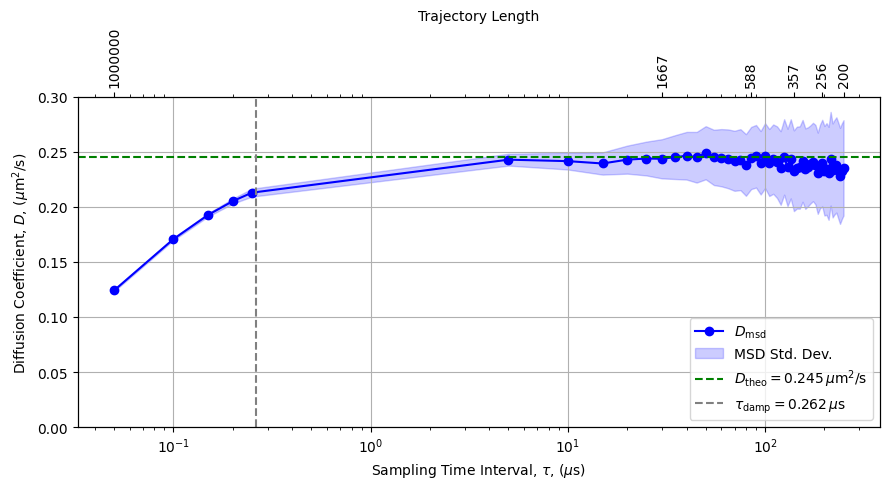

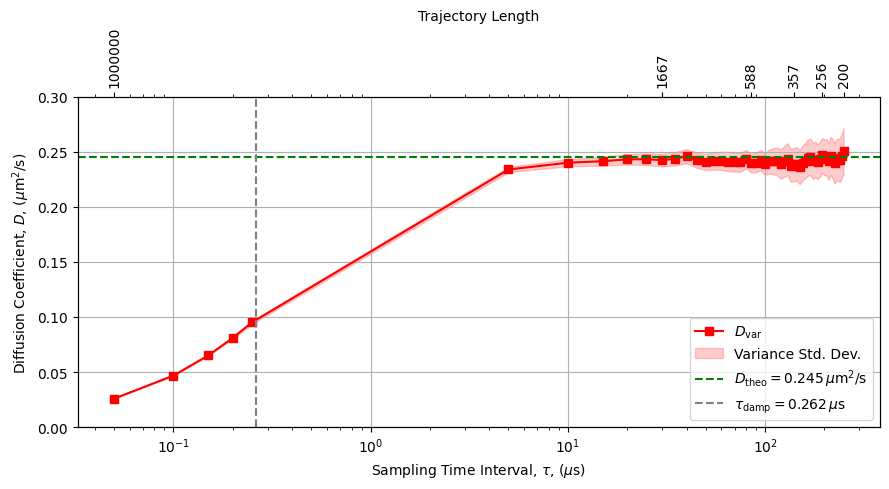

In [10]:
# === Load the dataset ===
file_path = "1mil_ave1.csv"
df = pd.read_csv(file_path, skiprows=1)

# === Clean column names ===
df.columns = df.columns.str.strip()

# === Convert relevant columns to numeric values ===
numeric_cols = [
    "tau", "D_theo", "D_msd", "D_var",
    "STD msd", "STD var", "Data points"
]
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

# === Convert units ===
df["D_theo"] *= 1e12
df["D_msd"] *= 1e12
df["D_var"] *= 1e12
df["STD msd"] *= 1e12
df["STD var"] *= 1e12
df["tau"] *= 1e6  # now in microseconds

# === Apply Gaussian smoothing to standard deviations ===
df["smoothed_std_msd"] = gaussian_filter1d(df["STD msd"].fillna(0), sigma=2)
df["smoothed_std_var"] = gaussian_filter1d(df["STD var"].fillna(0), sigma=2)

# === Drop NaNs ===
df_cleaned = df.dropna(subset=[
    "tau", "D_msd", "D_var", "smoothed_std_msd", "smoothed_std_var", "Data points"
])
df_cleaned["tau"] = pd.to_numeric(df_cleaned["tau"], errors='coerce')

# === Get theoretical D ===
D_theo = df_cleaned["D_theo"].iloc[0]

# === tau_damp location ===
tau_damp = 0.262  # microseconds

# === Optional y-axis range ===
ymin = 0
ymax = 0.3

# === Number of ticks for trajectory length axis ===
num_ticks = 6
selected_indices = np.linspace(0, len(df_cleaned) - 1, num=num_ticks, dtype=int)
tau_ticks = df_cleaned["tau"].iloc[selected_indices].values
traj_lengths = df_cleaned["Data points"].iloc[selected_indices].astype(int).astype(str).values

# === Plot MSD ===
fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(df_cleaned["tau"], df_cleaned["D_msd"], 'o-', color='blue', label=r"$D_{\text{msd}}$")
ax1.fill_between(df_cleaned["tau"],
                 df_cleaned["D_msd"] - df_cleaned["smoothed_std_msd"],
                 df_cleaned["D_msd"] + df_cleaned["smoothed_std_msd"],
                 color='blue', alpha=0.2, label="MSD Std. Dev.")
ax1.axhline(D_theo, color='green', linestyle='--',
            label=rf"$D_{{\text{{theo}}}} = {D_theo:.3f} \, \mu\text{{m}}^2/\text{{s}}$")
ax1.axvline(tau_damp, color='gray', linestyle='--', linewidth=1.5,
            label=rf"$\tau_{{\text{{damp}}}} = {tau_damp} \, \mu\text{{s}}$")

ax1.set_xscale('log')
ax1.set_xlabel(r"Sampling Time Interval, $\tau$, ($\mu$s)")
ax1.set_ylabel(r"Diffusion Coefficient, $D$, ($\mu\text{m}^2/\text{s}$)")
ax1.set_ylim(ymin, ymax)
ax1.grid(True)
ax1.legend()

ax2 = ax1.twiny()
ax2.set_xscale('log')
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(tau_ticks)
ax2.set_xticklabels(traj_lengths, rotation=90)
ax2.set_xlabel("Trajectory Length")

plt.tight_layout()
plt.show()

# === Plot Variance ===
fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(df_cleaned["tau"], df_cleaned["D_var"], 's-', color='red', label=r"$D_{\text{var}}$")
ax1.fill_between(df_cleaned["tau"],
                 df_cleaned["D_var"] - df_cleaned["smoothed_std_var"],
                 df_cleaned["D_var"] + df_cleaned["smoothed_std_var"],
                 color='red', alpha=0.2, label="Variance Std. Dev.")
ax1.axhline(D_theo, color='green', linestyle='--',
            label=rf"$D_{{\text{{theo}}}} = {D_theo:.3f} \, \mu\text{{m}}^2/\text{{s}}$")
ax1.axvline(tau_damp, color='gray', linestyle='--', linewidth=1.5,
            label=rf"$\tau_{{\text{{damp}}}} = {tau_damp} \, \mu\text{{s}}$")

ax1.set_xscale('log')
ax1.set_xlabel(r"Sampling Time Interval, $\tau$, ($\mu$s)")
ax1.set_ylabel(r"Diffusion Coefficient, $D$, ($\mu\text{m}^2/\text{s}$)")
ax1.set_ylim(ymin, ymax)
ax1.grid(True)
ax1.legend()

ax2 = ax1.twiny()
ax2.set_xscale('log')
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(tau_ticks)
ax2.set_xticklabels(traj_lengths, rotation=90)
ax2.set_xlabel("Trajectory Length")

plt.tight_layout()
plt.show()

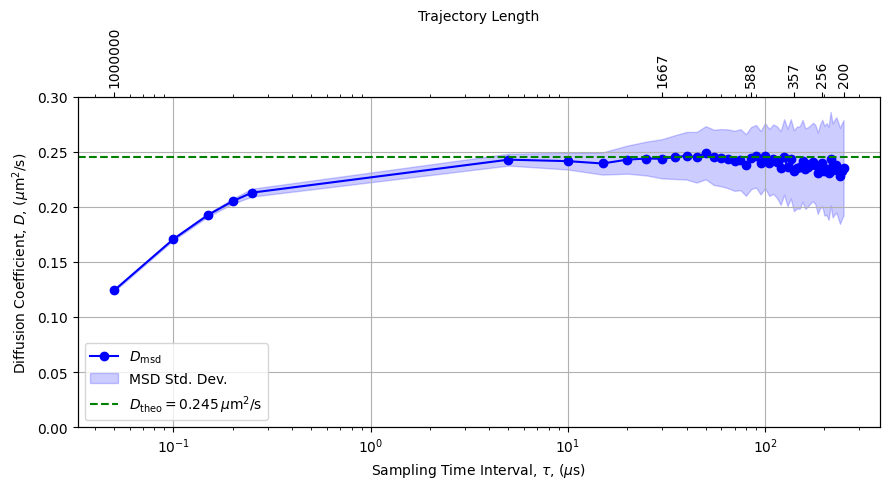

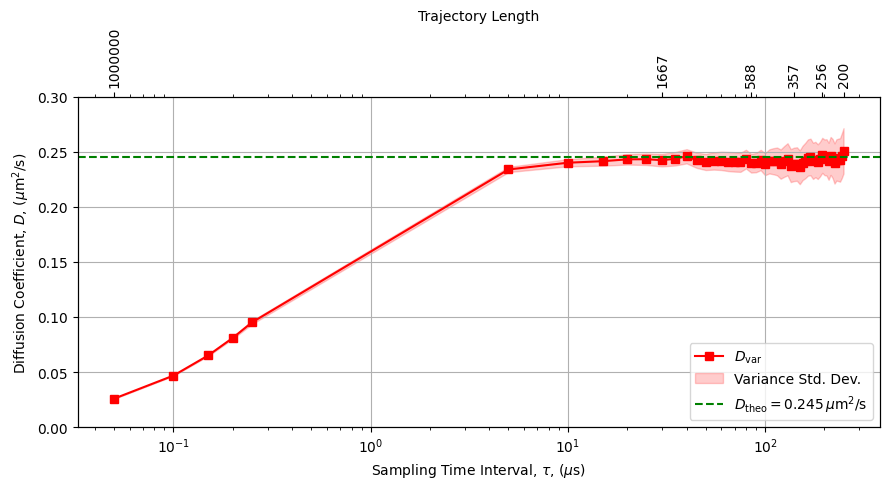

In [8]:
# === Load the dataset ===

file_path = "1mil_ave1.csv"
df = pd.read_csv(file_path, skiprows=1)
# === Clean column names ===
df.columns = df.columns.str.strip()

# === Convert relevant columns to numeric values ===
numeric_cols = [
    "tau", "D_theo", "D_msd", "D_var",
    "STD msd", "STD var", "Data points"
]
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

# === Convert units ===
df["D_theo"] *= 1e12
df["D_msd"] *= 1e12
df["D_var"] *= 1e12
df["STD msd"] *= 1e12
df["STD var"] *= 1e12
df["tau"] *= 1e6

# === Apply Gaussian smoothing to standard deviations ===
df["smoothed_std_msd"] = gaussian_filter1d(df["STD msd"].fillna(0), sigma=2)
df["smoothed_std_var"] = gaussian_filter1d(df["STD var"].fillna(0), sigma=2)

# === Drop NaNs ===
df_cleaned = df.dropna(subset=[
    "tau", "D_msd", "D_var", "smoothed_std_msd", "smoothed_std_var", "Data points"
])
df_cleaned["tau"] = pd.to_numeric(df_cleaned["tau"], errors='coerce')

# === Get theoretical D ===
D_theo = df_cleaned["D_theo"].iloc[0]

# === Optional y-axis range ===
ymin = 0
ymax = 0.3

# === Number of ticks for trajectory length axis ===
num_ticks = 6
selected_indices = np.linspace(0, len(df_cleaned) - 1, num=num_ticks, dtype=int)
tau_ticks = df_cleaned["tau"].iloc[selected_indices].values
traj_lengths = df_cleaned["Data points"].iloc[selected_indices].astype(int).astype(str).values

# === Plot MSD ===
fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(df_cleaned["tau"], df_cleaned["D_msd"], 'o-', color='blue', label=r"$D_{\text{msd}}$")
ax1.fill_between(df_cleaned["tau"],
                 df_cleaned["D_msd"] - df_cleaned["smoothed_std_msd"],
                 df_cleaned["D_msd"] + df_cleaned["smoothed_std_msd"],
                 color='blue', alpha=0.2, label="MSD Std. Dev.")
ax1.axhline(D_theo, color='green', linestyle='--',
            label=rf"$D_{{\text{{theo}}}} = {D_theo:.3f} \, \mu\text{{m}}^2/\text{{s}}$")
ax1.set_xscale('log')
ax1.set_xlabel(r"Sampling Time Interval, $\tau$, ($\mu$s)")
ax1.set_ylabel(r"Diffusion Coefficient, $D$, ($\mu\text{m}^2/\text{s}$)")
ax1.set_ylim(ymin, ymax)
ax1.grid(True)
ax1.legend()

ax2 = ax1.twiny()
ax2.set_xscale('log')
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(tau_ticks)
ax2.set_xticklabels(traj_lengths, rotation=90)
ax2.set_xlabel("Trajectory Length")

plt.tight_layout()
plt.show()

# === Plot Variance ===
fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(df_cleaned["tau"], df_cleaned["D_var"], 's-', color='red', label=r"$D_{\text{var}}$")
ax1.fill_between(df_cleaned["tau"],
                 df_cleaned["D_var"] - df_cleaned["smoothed_std_var"],
                 df_cleaned["D_var"] + df_cleaned["smoothed_std_var"],
                 color='red', alpha=0.2, label="Variance Std. Dev.")
ax1.axhline(D_theo, color='green', linestyle='--',
            label=rf"$D_{{\text{{theo}}}} = {D_theo:.3f} \, \mu\text{{m}}^2/\text{{s}}$")
ax1.set_xscale('log')
ax1.set_xlabel(r"Sampling Time Interval, $\tau$, ($\mu$s)")
ax1.set_ylabel(r"Diffusion Coefficient, $D$, ($\mu\text{m}^2/\text{s}$)")
ax1.set_ylim(ymin, ymax)
ax1.grid(True)
ax1.legend()

ax2 = ax1.twiny()
ax2.set_xscale('log')
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(tau_ticks)
ax2.set_xticklabels(traj_lengths, rotation=90)
ax2.set_xlabel("Trajectory Length")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d


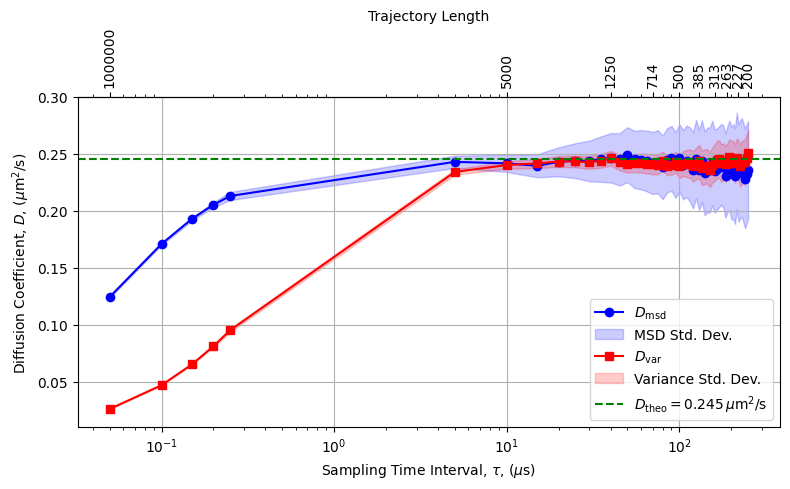

Closest tau for MSD to D_theo: 45.00 µs
Closest tau for VAR to D_theo: 200.00 µs
Average STD (MSD): 0.0289 µm²/s
Average STD (VAR): 0.0114 µm²/s


In [11]:

# --- Load and prepare dataset ---
file_path = "1mil_ave1.csv"
df = pd.read_csv(file_path, skiprows=1)

# Standardize column names
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Convert necessary columns to numeric
numeric_cols = [
    "tau", "d_theo", "d_msd", "d_var",
    "std_msd", "std_var", "data_points"
]
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

# Convert units
df["d_theo"] *= 1e12   # m²/s → µm²/s
df["d_msd"] *= 1e12
df["d_var"] *= 1e12
df["tau"] *= 1e6       # seconds → microseconds
df["std_msd"] *= 1e12
df["std_var"] *= 1e12

# Smooth error margins using standard deviations
df["smoothed_error_margin_msd"] = gaussian_filter1d(df["std_msd"].fillna(0), sigma=2)
df["smoothed_error_margin_var"] = gaussian_filter1d(df["std_var"].fillna(0), sigma=2)

# Cleaned DataFrame for plotting
df_cleaned = df.dropna(subset=[
    "tau", "d_msd", "d_var",
    "smoothed_error_margin_msd", "smoothed_error_margin_var",
    "data_points"
])

# Theoretical value (constant)
D_theo = 0.245  # µm²/s

# --- Plotting ---
fig, ax1 = plt.subplots(figsize=(8, 5))

# X-axis: tau
ax1.set_xscale('log')
ax1.set_xlabel(r'Sampling Time Interval, $\tau$, ($\mu$s)')
ax1.set_ylabel(r'Diffusion Coefficient, $D$, ($\mu\text{m}^2/\text{s}$)')

# Plot D_msd
ax1.plot(df_cleaned["tau"], df_cleaned["d_msd"], marker='o', linestyle='-', label=r"$D_{\mathrm{msd}}$", color='b')
ax1.fill_between(df_cleaned["tau"],
                 df_cleaned["d_msd"] - df_cleaned["smoothed_error_margin_msd"],
                 df_cleaned["d_msd"] + df_cleaned["smoothed_error_margin_msd"],
                 color='b', alpha=0.2, label="MSD Std. Dev.")

# Plot D_var
ax1.plot(df_cleaned["tau"], df_cleaned["d_var"], marker='s', linestyle='-', label=r"$D_{\mathrm{var}}$", color='r')
ax1.fill_between(df_cleaned["tau"],
                 df_cleaned["d_var"] - df_cleaned["smoothed_error_margin_var"],
                 df_cleaned["d_var"] + df_cleaned["smoothed_error_margin_var"],
                 color='r', alpha=0.2, label="Variance Std. Dev.")

# Theoretical line
ax1.axhline(D_theo, color='g', linestyle='--', label=fr"$D_{{\mathrm{{theo}}}} = {D_theo} \, \mu\mathrm{{m}}^2/\mathrm{{s}}$")

# Secondary x-axis: Data Points
secax = ax1.secondary_xaxis('top')
secax.set_xlabel("Trajectory Length")
num_ticks = 10
tick_indices = np.linspace(0, len(df_cleaned) - 1, num_ticks, dtype=int)
tick_locs = df_cleaned["tau"].iloc[tick_indices]
tick_labels = df_cleaned["data_points"].iloc[tick_indices].astype(int)

secax.set_xticks(tick_locs)
secax.set_xticklabels(tick_labels, rotation=90, ha='center')

# Legend and layout
ax1.legend()
ax1.grid(True)
ax1.set_ylim(0.01, 0.30)
plt.tight_layout()
plt.show()

# --- Find closest values to theoretical ---
df_cleaned["abs_diff_msd"] = abs(df_cleaned["d_msd"] - D_theo)
df_cleaned["abs_diff_var"] = abs(df_cleaned["d_var"] - D_theo)
avg_std_msd = df_cleaned["std_msd"].mean()
avg_std_var = df_cleaned["std_var"].mean()

closest_tau_msd = df_cleaned.loc[df_cleaned["abs_diff_msd"].idxmin(), "tau"]
closest_tau_var = df_cleaned.loc[df_cleaned["abs_diff_var"].idxmin(), "tau"]

print(f"Closest tau for MSD to D_theo: {closest_tau_msd:.2f} µs")
print(f"Closest tau for VAR to D_theo: {closest_tau_var:.2f} µs")
print(f"Average STD (MSD): {avg_std_msd:.4f} µm²/s")
print(f"Average STD (VAR): {avg_std_var:.4f} µm²/s")

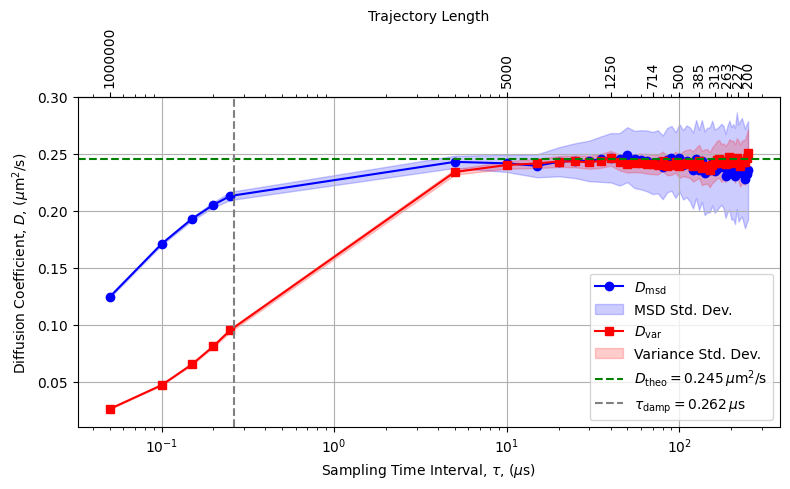

Closest tau for MSD to D_theo: 45.00 µs
Closest tau for VAR to D_theo: 200.00 µs
Average STD (MSD): 0.0289 µm²/s
Average STD (VAR): 0.0114 µm²/s


In [12]:
# --- Load and prepare dataset ---
file_path = "1mil_ave1.csv"
df = pd.read_csv(file_path, skiprows=1)

# Standardize column names
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Convert necessary columns to numeric
numeric_cols = [
    "tau", "d_theo", "d_msd", "d_var",
    "std_msd", "std_var", "data_points"
]
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

# Convert units
df["d_theo"] *= 1e12   # m²/s → µm²/s
df["d_msd"] *= 1e12
df["d_var"] *= 1e12
df["tau"] *= 1e6       # seconds → microseconds
df["std_msd"] *= 1e12
df["std_var"] *= 1e12

# Smooth error margins using standard deviations
df["smoothed_error_margin_msd"] = gaussian_filter1d(df["std_msd"].fillna(0), sigma=2)
df["smoothed_error_margin_var"] = gaussian_filter1d(df["std_var"].fillna(0), sigma=2)

# Cleaned DataFrame for plotting
df_cleaned = df.dropna(subset=[
    "tau", "d_msd", "d_var",
    "smoothed_error_margin_msd", "smoothed_error_margin_var",
    "data_points"
])

# Theoretical value (constant)
D_theo = 0.245  # µm²/s
tau_damp = 0.262  # µs

# --- Plotting ---
fig, ax1 = plt.subplots(figsize=(8, 5))

# X-axis: tau
ax1.set_xscale('log')
ax1.set_xlabel(r'Sampling Time Interval, $\tau$, ($\mu$s)')
ax1.set_ylabel(r'Diffusion Coefficient, $D$, ($\mu\text{m}^2/\text{s}$)')

# Plot D_msd
ax1.plot(df_cleaned["tau"], df_cleaned["d_msd"], marker='o', linestyle='-', label=r"$D_{\mathrm{msd}}$", color='b')
ax1.fill_between(df_cleaned["tau"],
                 df_cleaned["d_msd"] - df_cleaned["smoothed_error_margin_msd"],
                 df_cleaned["d_msd"] + df_cleaned["smoothed_error_margin_msd"],
                 color='b', alpha=0.2, label="MSD Std. Dev.")

# Plot D_var
ax1.plot(df_cleaned["tau"], df_cleaned["d_var"], marker='s', linestyle='-', label=r"$D_{\mathrm{var}}$", color='r')
ax1.fill_between(df_cleaned["tau"],
                 df_cleaned["d_var"] - df_cleaned["smoothed_error_margin_var"],
                 df_cleaned["d_var"] + df_cleaned["smoothed_error_margin_var"],
                 color='r', alpha=0.2, label="Variance Std. Dev.")

# Theoretical line
ax1.axhline(D_theo, color='g', linestyle='--',
            label=fr"$D_{{\mathrm{{theo}}}} = {D_theo} \, \mu\mathrm{{m}}^2/\mathrm{{s}}$")

# Vertical dashed line for tau_damp
ax1.axvline(tau_damp, color='gray', linestyle='--', linewidth=1.5,
            label=fr"$\tau_{{\mathrm{{damp}}}} = {tau_damp} \, \mu\mathrm{{s}}$")

# Secondary x-axis: Data Points
secax = ax1.secondary_xaxis('top')
secax.set_xlabel("Trajectory Length")
num_ticks = 10
tick_indices = np.linspace(0, len(df_cleaned) - 1, num_ticks, dtype=int)
tick_locs = df_cleaned["tau"].iloc[tick_indices]
tick_labels = df_cleaned["data_points"].iloc[tick_indices].astype(int)
secax.set_xticks(tick_locs)
secax.set_xticklabels(tick_labels, rotation=90, ha='center')

# Legend and layout
ax1.legend()
ax1.grid(True)
ax1.set_ylim(0.01, 0.30)
plt.tight_layout()
plt.show()

# --- Find closest values to theoretical ---
df_cleaned["abs_diff_msd"] = abs(df_cleaned["d_msd"] - D_theo)
df_cleaned["abs_diff_var"] = abs(df_cleaned["d_var"] - D_theo)
avg_std_msd = df_cleaned["std_msd"].mean()
avg_std_var = df_cleaned["std_var"].mean()

closest_tau_msd = df_cleaned.loc[df_cleaned["abs_diff_msd"].idxmin(), "tau"]
closest_tau_var = df_cleaned.loc[df_cleaned["abs_diff_var"].idxmin(), "tau"]

print(f"Closest tau for MSD to D_theo: {closest_tau_msd:.2f} µs")
print(f"Closest tau for VAR to D_theo: {closest_tau_var:.2f} µs")
print(f"Average STD (MSD): {avg_std_msd:.4f} µm²/s")
print(f"Average STD (VAR): {avg_std_var:.4f} µm²/s")